# Домашнее задание 9. Панельные модели экспорта и поиск недоосвоенных рынков

**Оценивание.** `Неделя 9_НС_Поиск экспортных рынков_ДЗ.ipynb` весит 50% оценки. PDF-отчёт также весит 50% оценки. Максимальный балл за домашнее задание составляет 10 баллов.

**Пояснение к разбалловке.** За все пункты синего уровня можно получить максимум 5 баллов из 10. Пункты синего и красного уровней дают максимум 7 баллов из 10. Пункты всех трёх уровней дают максимум 10 баллов из 10. Пункт 3г даёт 1 бонусный балл чёрного уровня, но итоговый балл за домашнее задание всё равно не может превышать 10. Дополнительная идея с кластеризацией и расстоянием в конце задания выполняется только по желанию и не оценивается.


In [ ]:
# @title Служебная загрузка данных — нажми ▶ { display-mode: "form" }
# Запусти эту ячейку перед выполнением заданий. Это данность -- как и в семинаре 9,
# разбираться в реализации не обязательно, важно знать, что возвращает каждая функция.
!pip install linearmodels
import requests
import re
import numpy as np
import pandas as pd
import statsmodels.api as sm
from linearmodels.panel import PanelOLS, RandomEffects
from scipy import stats
pd.options.display.float_format = "{:,.3f}".format

OEC_BASE_URL = "https://api-v2.oec.world/tesseract"
TRADE_CUBE = "trade_i_baci_a_17"

def load_oec_members(level, search=None, limit="100,0", cube=TRADE_CUBE):
    params = {"cube": cube, "level": level, "limit": limit}
    if search is not None:
        params["search"] = search
    response = requests.get(f"{OEC_BASE_URL}/members.jsonrecords", params=params, timeout=60)
    response.raise_for_status()
    return pd.DataFrame(response.json()["members"]), response.url

def load_oec_data(drilldowns, include=None, measures="Trade Value", cube=TRADE_CUBE, limit=50000):
    params = {"cube": cube, "drilldowns": ",".join(drilldowns), "measures": measures,
              "locale": "en", "parents": "false", "limit": f"{limit},0"}
    if include:
        params["include"] = ";".join(include)
    response = requests.get(f"{OEC_BASE_URL}/data.jsonrecords", params=params, timeout=120)
    response.raise_for_status()
    payload = response.json()
    table = pd.DataFrame(payload["data"])
    if table.empty:
        raise ValueError("OEC вернул пустую таблицу: проверь код товара, страну-экспортёра и годы.")
    return table, payload.get("annotations", {}), response.url

def load_wdi(indicator, start_year, end_year):
    response = requests.get(f"https://api.worldbank.org/v2/country/all/indicator/{indicator}",
        params={"format": "json", "date": f"{start_year}:{end_year}", "per_page": 20000}, timeout=120)
    response.raise_for_status()
    payload = response.json()
    if not payload or len(payload) < 2 or payload[1] is None:
        raise ValueError(f"World Bank API вернул пустой ответ для индикатора {indicator}.")
    table = pd.DataFrame({"ISO3": r["countryiso3code"], "Year": int(r["date"]), "Значение": r["value"]}
                          for r in payload[1] if r["countryiso3code"] and r["value"] is not None)
    return table, response.url

def find_country_id(country_name, level="Exporter Country", cube=TRADE_CUBE):
    # Ищет ID страны в справочнике cube по названию, например 'Russia'. Схема ответа OEC:
    # столбцы 'key' (технический ID) и 'caption' (человекочитаемое название).
    members, _ = load_oec_members(level, search=country_name, cube=cube)
    if members.empty:
        raise ValueError(f"Страна '{country_name}' не найдена по уровню '{level}', уточни запрос.")
    match = members.loc[members["caption"].str.contains(country_name, case=False, na=False)]
    row = match.iloc[0] if not match.empty else members.iloc[0]
    return row["key"], row

def find_product_id(product_search, product_level="HS6", name_fragment=None, cube=TRADE_CUBE):
    # Ищет ID товара в справочнике cube (уровень HS6/HS4/...) по свободному текстовому запросу.
    # ВАЖНО: 'key' в OEC для товаров -- это НЕ голый HS-код. Для мороженого (HS6 210500) реальный
    # key равен '4210500': это код товарной секции (4 -- Prepared Foodstuffs) + сам HS6-код.
    # Поэтому товар всегда ищем через members-справочник, а не подставляем HS-код напрямую.
    members, _ = load_oec_members(product_level, search=product_search, cube=cube)
    if members.empty:
        raise ValueError(f"Товар '{product_search}' не найден на уровне {product_level}, уточни запрос.")
    if name_fragment:
        match = members.loc[members["caption"].str.contains(name_fragment, case=False, na=False)]
        row = match.iloc[0] if not match.empty else members.iloc[0]
    else:
        row = members.iloc[0]
    return row["key"], row

def load_bilateral_exports(exporter_name, product_search, product_level="HS6", name_fragment=None,
                            start_year=2016, end_year=2023, cube=TRADE_CUBE):
    # Экспорт товара (найденного по product_search на уровне product_level) из страны exporter_name
    # по всем странам-партнёрам за start_year..end_year. Возвращает панель (Year, ISO3, Страна, Exports).
    exporter_id, _ = find_country_id(exporter_name, cube=cube)
    product_id, _ = find_product_id(product_search, product_level=product_level,
                                     name_fragment=name_fragment, cube=cube)
    years = ",".join(str(y) for y in range(start_year, end_year + 1))
    include = [f"{product_level}:{product_id}", f"Exporter Country:{exporter_id}", f"Year:{years}"]
    raw, meta, url = load_oec_data(["Year", "Importer Country", product_level], include, cube=cube)
    raw["ISO3"] = raw["Importer Country ID"].str[-3:].str.upper()
    panel = (raw.groupby(["Year", "ISO3", "Importer Country"], as_index=False)["Trade Value"].sum()
                .rename(columns={"Importer Country": "Страна", "Trade Value": "Exports"}))
    return panel.sort_values(["ISO3", "Year"]), {"dataset_name": meta.get("dataset_name"), "url": url}

def attach_wdi(panel, indicator, col_name, start_year=2016, end_year=2023):
    # Присоединяет к панели (со столбцами ISO3, Year) один показатель Всемирного банка.
    wdi, url = load_wdi(indicator, start_year, end_year)
    wdi = wdi.rename(columns={"Значение": col_name})
    return panel.merge(wdi[["ISO3", "Year", col_name]], on=["ISO3", "Year"], how="left"), url

# Параметры демонстрации -- в реальном ДЗ меняешь только эти строки на свой товар.
EXPORTER = "Russia"
PRODUCT_SEARCH, PRODUCT_LEVEL, PRODUCT_NAME_FRAGMENT = "ice cream", "HS6", "Ice cream"
START_YEAR, END_YEAR = 2016, 2023
print("Загрузчики готовы.")


Загрузчики готовы.


In [ ]:
# @title Сохранённые данные OEC / BACI и WDI { display-mode: "form" }
import base64
import gzip
import json

# WDI сохранены по всем партнёрам в торговой выгрузке, включая пропуски.
REFRESH_DATA = False
snapshot = (
    '...'
    'U+OB5eYPAgA='
)
frozen_data = json.loads(gzip.decompress(base64.b64decode(snapshot)))


### загружаем

In [ ]:
# в общем все аналогично прошлым дз
import json
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
from IPython.display import Markdown, display
from linearmodels.panel import PanelOLS, RandomEffects
from linearmodels.panel.utility import AbsorbingEffectWarning
from scipy import stats

pd.options.display.float_format = '{:,.5g}'.format
START, END = 2018, 2024
YEARS = list(range(START, END + 1))
CUBE = 'trade_i_baci_a_17'
INDICATORS = {'GDP': 'NY.GDP.MKTP.CD', 'Population': 'SP.POP.TOTL', 'ER': 'PA.NUS.FCRF'}
OEC_HOSTS = ('https://api.oec.world/tesseract', 'https://api-v2.oec.world/tesseract')
sources = []
session = requests.Session()
session.headers.update({'User-Agent': 'Mozilla/5.0'})

def load_json(label, urls, params):
    if not REFRESH_DATA:
        saved = frozen_data[label]
    else:
        errors = []
        for url in urls:
            try:
                response = session.get(url, params=params, timeout=(12, 90))
                response.raise_for_status()
                payload = response.json()
                saved = {'url': response.url, 'retrieved_utc': datetime.now(timezone.utc).isoformat(),
                         'payload': payload}
                break
            except (requests.RequestException, ValueError) as exc:
                errors.append(str(exc))
        else:
            raise RuntimeError(f'Не удалось получить {label}. ' + ' | '.join(errors))
    sources.append({'Набор': label, 'URL': saved['url'], 'Получено (UTC)': saved['retrieved_utc']})
    return saved['payload']

def oec_member(level, search, caption):
    payload = load_json(f'member_{level.replace(" ", "_")}',
                        [f'{host}/members.jsonrecords' for host in OEC_HOSTS],
                        {'cube': CUBE, 'level': level, 'search': search, 'limit': '100,0'})
    matches = [str(row['key']) for row in payload['members']
               if row['caption'].strip().casefold() == caption.casefold()]
    if len(matches) != 1:
        raise ValueError(f'В справочнике OEC не найдено однозначное совпадение для {caption}: {matches}')
    return matches[0]

def load_wdi(name, indicator):
    url = f'https://api.worldbank.org/v2/country/all/indicator/{indicator}'
    payload = load_json(indicator, [url], {'format': 'json', 'date': f'{START}:{END}', 'per_page': 20000})
    if len(payload) != 2 or not payload[1] or int(payload[0]['pages']) != 1:
        raise ValueError(f'Неполный ответ WDI по {indicator}')
    table = pd.DataFrame((r['countryiso3code'], int(r['date']), r['value']) for r in payload[1]
                         if r['countryiso3code'] and r['value'] is not None)
    table.columns = ['ISO3', 'Year', name]
    assert not table.duplicated(['ISO3', 'Year']).any(), indicator
    return table

## **[Синий, 5 баллов]** Задание 1. Панель данных и pooled OLS

### **[Синий, 1 балл]** Пункт 1а. Структура панели

Загрузи панель экспорта товара из России по странам-импортёрам и проверь её на дубликаты, число стран и лет, сбалансированность.


In [ ]:
# Загрузи панель экспорта товара из России и проверь её структуру.
# trade_panel, meta = ...
# Выведи период, число стран, число строк, дубликаты и число лет на страну.
product_id = oec_member('HS6', 'honey', 'Natural Honey')
exporter_id = oec_member('Exporter Country', 'Russia', 'Russia')
assert product_id == '1040900' and exporter_id.upper().endswith('RUS')
raw = load_json('trade_rus_honey_2018_2024', [f'{host}/data.jsonrecords' for host in OEC_HOSTS],
                {'cube': CUBE, 'drilldowns': 'Year,Importer Country,HS6', 'measures': 'Trade Value',
                 'locale': 'en', 'parents': 'false', 'limit': '50000,0',
                 'include': f'HS6:{product_id};Exporter Country:{exporter_id};Year:' + ','.join(map(str, YEARS))})
trade = (pd.DataFrame(raw['data']).rename(columns={'Importer Country': 'Страна', 'Trade Value': 'Exports'})
         [['Year','Importer Country ID','Страна','Exports']].copy())
trade['ISO3'] = trade.pop('Importer Country ID').astype(str).str[-3:].str.upper()
trade['Year'] = trade['Year'].astype(int)
assert sorted(trade.Year.unique()) == YEARS and len(trade) < 50000
assert trade.ISO3.str.fullmatch(r'[A-Z]{3}').all()
keys = ['ISO3', 'Year']
duplicates = int(trade.duplicated(keys).sum())
print(f'Период {START}–{END}, партнёров {trade.ISO3.nunique()}, строк {len(trade)}, дубликатов {duplicates}.')
assert duplicates == 0
T = trade.groupby('ISO3').Year.nunique()
display(T.value_counts().sort_index().rename_axis('Число лет').to_frame('Число стран'))
display(trade.groupby('Year').agg(Стран=('ISO3','size'), Экспорт_USD=('Exports','sum')))
print(f'Сбалансированность: {bool(T.eq(len(YEARS)).all())}. Стран с одним годом: {sum(T == 1)}.')

Период 2018–2024, партнёров 67, строк 252, дубликатов 0.


,Число стран
Число лет,
1,16
2,10
3,7
4,8
5,6
6,7
7,13


,Стран,Экспорт_USD
Year,,
2018,30,4.668e+06
2019,39,5.5395e+06
2020,34,5.1781e+06
2021,51,6.9553e+06
2022,34,5.4564e+06
2023,36,6.0997e+06
2024,28,7.3148e+06


Сбалансированность: False. Стран с одним годом: 16.


Используем зарегистрированные потоки BACI, пустая пара «страна–год» может показывать отсутствие поставки или особенности учета (такие пары не заполняем нулями), Число наблюдений на страну проверяем и после соединения источников

### **[Синий, 1 балл]** Пункт 1б. Итоговая панель country×year

Присоедини ВВП (`NY.GDP.MKTP.CD`), население (`SP.POP.TOTL`) и обменный курс (`PA.NUS.FCRF`) из World Bank.


In [ ]:
# Присоедини ВВП, население и обменный курс из World Bank.
# Сформируй общую выборку для всех моделей и создай логарифмы.
panel = trade.copy()
for var, indicator in INDICATORS.items():
    wdi = load_wdi(var, indicator)
    panel = panel.merge(wdi, on=keys, how='left', validate='one_to_one')
base_cols = ['Exports', 'GDP', 'Population', 'ER']
invalid = panel[base_cols].isna() | ~np.isfinite(panel[base_cols]) | panel[base_cols].le(0)
display(pd.DataFrame({'Пропуски': panel[base_cols].isna().sum(),
                      'Неположительные': panel[base_cols].le(0).sum(),
                      'Исключены по признаку': invalid.sum()}))
complete = panel.loc[~invalid.any(axis=1)].copy()
counts = complete.groupby('ISO3').Year.transform('size')
common = complete.loc[counts.ge(2)].copy()
print(f'Исключено при очистке: {len(panel)-len(complete)}; одногодичных строк: {sum(counts == 1)}.')
print(f'Общая панель: {len(common)} строк, {common.ISO3.nunique()} стран, '
      f'{common.Year.min()}–{common.Year.max()}.')
print(f'Охват стоимости: {common.Exports.sum()/trade.Exports.sum():.2%}.')
assert int(common.Year.max()) == END
display(common.groupby('Year').size().rename('Наблюдений'))
display(pd.DataFrame(sources))
for col in ['Exports','GDP','Population']:
    common['ln_'+col] = np.log(common[col])
common = common.set_index(keys).sort_index()
xcols = ['ln_GDP', 'ln_Population', 'ER']
y = common.ln_Exports
X = sm.add_constant(common[xcols])

,Пропуски,Неположительные,Исключены по признаку
Exports,0,0,0
GDP,7,0,7
Population,7,0,7
ER,9,0,9


Исключено при очистке: 9; одногодичных строк: 16.
Общая панель: 227 строк, 49 стран, 2018–2024.
Охват стоимости: 99.22%.


,Наблюдений
Year,
2018,29
2019,34
2020,30
2021,42
2022,33
2023,33
2024,26


,Набор,URL,Получено (UTC)
0,member_HS6,https://api.oec.world/tesseract/members?cube=t...,2026-11-16T14:34:24.445182+00:00
1,member_Exporter_Country,https://api.oec.world/tesseract/members?cube=t...,2026-11-16T14:34:24.327196+00:00
2,trade_rus_honey_2018_2024,https://api.oec.world/tesseract/data.jsonrecor...,2026-11-16T14:34:25.015098+00:00
3,NY.GDP.MKTP.CD,https://api.worldbank.org/v2/country/all/indic...,2026-11-16T14:34:33.446089+00:00
4,SP.POP.TOTL,https://api.worldbank.org/v2/country/all/indic...,2026-11-16T14:34:23.865887+00:00
5,PA.NUS.FCRF,https://api.worldbank.org/v2/country/all/indic...,2026-11-16T14:34:33.397955+00:00


Общая выборка исключает одногодичных импортёров после очистки, поскольку они не дают внутристранового сравнения. Все модели используют ровно эту выборку

### **[Синий, 1.5 балла]** Пункт 1в. Оценка pooled OLS

$$\ln(\text{Exports}_{it}) = b_0 + b_1\ln(\text{GDP}_{it}) + b_2\ln(\text{Population}_{it}) + b_3\,\text{ER}_{it} + u_{it}$$


In [ ]:
# Оцени pooled OLS с робастными стандартными ошибками (HC1).
# Выведи коэффициенты, se, p-value, R² и N.
def coefficients(params, se, p):
    return pd.DataFrame({'Коэффициент': params, 'Ст. ошибка': se, 'p': p})

pooled = sm.OLS(y, X).fit(cov_type='HC1')
display(coefficients(pooled.params, pooled.bse, pooled.pvalues))
print(f'R² = {pooled.rsquared:.4f}, N = {int(pooled.nobs)}.')

,Коэффициент,Ст. ошибка,p
const,5.6232,2.6241,0.032124
ln_GDP,-0.9586,0.21923,1.228e-05
ln_Population,1.7548,0.25202,3.3343e-12
ER,6.5593e-05,7.0062e-05,0.34916


R² = 0.2227, N = 227.


### **[Синий, 1.5 балла]** Пункт 1г. Интерпретация pooled OLS

Проинтерпретируй знак, экономический смысл и статистическую значимость каждого коэффициента.


In [ ]:
# Если в pooled OLS есть неожиданный результат, сформулируй проверяемую гипотезу
# и проверь её хотя бы одним простым способом на тех же данных.
def sig(p):
    return 'значим на уровне 5%' if p < .05 else 'p ≥ 0,05'

labels = {'ln_GDP': 'ВВП', 'ln_Population': 'Население', 'ER': 'Официальный курс'}
for var, label in labels.items():
    b, p = pooled.params[var], pooled.pvalues[var]
    pct = 100*np.expm1(b*np.log(1.01) if var != 'ER' else b)
    change = '+1% признака' if var != 'ER' else '+1 единица местной валюты за доллар'
    display(Markdown(f'**{label}.** {change}: изменение условного уровня exp(прогноза) '
                     f'на {pct:+.4g}% при прочих равных (β = {b:+.4g}, p = {p:.3g}, {sig(p)})'))
display(Markdown(f'Константа {pooled.params["const"]:.3f} (p = {pooled.pvalues["const"]:.3g}) '
                 'соответствует ВВП в 1 доллар, населению в 1 человека и нулевому курсу. '
                 'Этот набор значений экономического смысла для нашей панели не имеет'))

# Гипотеза: коэффициент при населении при данном ВВП отражает различия дохода на человека.
alternative = common.assign(ln_GDP_pc=common.ln_GDP-common.ln_Population)
alt = sm.OLS(y, sm.add_constant(alternative[['ln_GDP','ln_GDP_pc','ER']])).fit(cov_type='HC1')
assert np.allclose(alt.fittedvalues, pooled.fittedvalues)
cor = common[['ln_GDP','ln_Population']].corr().iloc[0,1]
display(coefficients(alt.params, alt.bse, alt.pvalues))
display(Markdown(f'Гипотеза о роли дохода проверяется перепараметризацией: '
                 f'при фиксированном ВВП прирост населения означает снижение ВВП на человека '
                 f'Корреляция log ВВП и log населения равна {cor:.3f} '
                 f'Коэффициент дохода на человека равен {alt.params["ln_GDP_pc"]:+.3f} '
                 f'(p = {alt.pvalues["ln_GDP_pc"]:.3g}) '
                 'Это уточняет смысл коэффициента, однако использует те же данные и даёт те же fitted'))
# Проверка, насколько курс зависит от масштаба валюты: заменяем уровень индексом к первому году страны
first_rate = common.groupby(level='ISO3').ER.transform('first')
relative = X.assign(ER=100*np.log(common.ER/first_rate))
rate_check = sm.OLS(y, relative).fit(cov_type='HC1')
print(f'Для курса, пересчитанного как 100 × ln(курс / первый курс страны): '
      f'β = {rate_check.params.ER:+.5g}, p = {rate_check.pvalues.ER:.4g}')

**ВВП.** +1% признака: изменение условного уровня exp(прогноза) на -0.9493% при прочих равных (β = -0.9586, p = 1.23e-05, значим на уровне 5%)

**Население.** +1% признака: изменение условного уровня exp(прогноза) на +1.761% при прочих равных (β = +1.755, p = 3.33e-12, значим на уровне 5%)

**Официальный курс.** +1 единица местной валюты за доллар: изменение условного уровня exp(прогноза) на +0.00656% при прочих равных (β = +6.559e-05, p = 0.349, p ≥ 0,05)

Константа 5.623 (p = 0.0321) соответствует ВВП в 1 доллар, населению в 1 человека и нулевому курсу. Этот набор значений экономического смысла для нашей панели не имеет

,Коэффициент,Ст. ошибка,p
const,5.6232,2.6241,0.032124
ln_GDP,0.79621,0.10127,3.7641e-15
ln_GDP_pc,-1.7548,0.25202,3.3343e-12
ER,6.5593e-05,7.0062e-05,0.34916


Гипотеза о роли дохода проверяется перепараметризацией: при фиксированном ВВП прирост населения означает снижение ВВП на человека Корреляция log ВВП и log населения равна 0.838 Коэффициент дохода на человека равен -1.755 (p = 3.33e-12) Это уточняет смысл коэффициента, однако использует те же данные и даёт те же fitted

Для курса, пересчитанного как 100 × ln(курс / первый курс страны): β = -0.036755, p = 0.1348


Для предварительного отбора смотрим на размер экономики вместе с фактическим импортом меда, ВВП и население измеряют размер и покупательную способность лишь косвенно
Но сравнить привлекательность стран по уровням номинальных курсов тяжко из-за разного масштаба денежных единиц

## **[Красный, 2 балла]** Задание 2. Модель с фиксированными эффектами

### **[Красный, 0.5 балла]** Пункт 2а. Экономическая мотивация

Какие ненаблюдаемые характеристики твоей страны-импортёра могут быть постоянными во времени? Почему они могут коррелировать с ВВП, населением или курсом?


Постоянные различия между импортерами включают положение относительно России, сложившиеся каналы сбыта, предпочтения покупателей и базовую структуру потребления меда


История связей мб особенно важна для соседей России. Более крупные и богатые рынки могут иметь иные каналы розницы, а валютная единица и режим курса связаны с историей страны. Страновые эффекты позволяют учесть устойчивую часть таких различий. Годовые эффекты улавливают общие для покупателей изменения, например общую динамику предложения и цен российского экспорта

### **[Красный, 1 балл]** Пункт 2б. Оценка FE-модели

Оцени модель с фиксированными эффектами по странам и годам. Выбери свой постоянный признак (участие в союзе, общая граница и так далее), попробуй добавить его в FE и объясни результат.


 Используем ту же панель «импортёр * год», что и в pooled OLS. Для каждого импортёра модель допускает собственный постоянный уровень поставок, а для каждого года общий сдвиг, одинаковый для всех стран

$$
\ln X_{it}=\alpha_i+\lambda_t+\beta_1\ln GDP_{it}+\beta_2\ln Pop_{it}+\beta_3 ER_{it}+u_{it}.
$$

Страновой эффект $\alpha_i$ учитывает устойчивые особенности рынка, например географию и сложившиеся каналы поставок. Годовой эффект $\lambda_t$ учитывает общие изменения, например изменение предложения российского мёда. Коэффициенты оцениваются по изменениям внутри импортёра с учётом общих сдвигов по годам
 (Стандартные ошибки кластеризуем по импортерам, чтобы допустить зависимость ошибок одной страны в разные годы)

In [ ]:
# Оцени FE-модель со страновыми и годовыми эффектами.
# panel_idx = ...
# fe_res = ...
fe_model = PanelOLS(y, X, entity_effects=True, time_effects=True)
fe = fe_model.fit(cov_type='clustered', cluster_entity=True)
assert fe.nobs == pooled.nobs == len(common)
assert fe.fitted_values.index.equals(common.index)

display(coefficients(fe.params, fe.std_errors, fe.pvalues))
print(f'N = {fe.nobs}, импортёров = {common.index.get_level_values("ISO3").nunique()}.')
print(f'R² within = {fe.rsquared_within:.4f}; R² с учётом эффектов = {fe.rsquared_inclusive:.4f}.')

,Коэффициент,Ст. ошибка,p
const,169.35,183.78,0.35812
ln_GDP,4.1708,2.3168,0.073604
ln_Population,-16.416,11.938,0.17093
ER,0.0015523,0.00047273,0.0012453


N = 227, импортёров = 49.
R² within = -0.0323; R² с учётом эффектов = 0.7577.


При неизменных населении и курсе рост ВВП импортёра на 1% связан примерно с ростом условного уровня поставок на 4,2%. Для населения оценка отрицательная: рост населения на 1% при неизменном ВВП связан примерно со снижением на 16% по линейному приближению. Для обоих коэффициентов $p>0{,}05$. Оценка курса положительна и значима на уровне 5%. Рост курса на одну единицу местной валюты за доллар связан примерно с ростом условного уровня поставок на 0,16%. У разных валют эта единица имеет разный масштаб

**Теперь проверка постоянного признака**

 Берем сухопутную границу с Россией. Для каждого импортера проверяем, что признак одинаков во все наблюдаемые годы. Сначала пробуем оценить расширенную FE с настройками по умолчанию. Затем явно разрешаем исключить поглощённый признак и сверяем оценки с первой ячейкой

In [ ]:
# Создай выбранный постоянный признак страны и попробуй добавить его в FE.
# Объясни, что произошло.
# Сухопутное соседство с Россией. Включены границы Калининградской области и КНДР.
neighbors = {'NOR','FIN','EST','LVA','LTU','POL','BLR','UKR','GEO','AZE','KAZ','CHN','MNG','PRK'}
common['Border'] = common.index.get_level_values('ISO3').isin(neighbors).astype(int)
assert common.groupby(level='ISO3').Border.nunique().eq(1).all() and common.Border.nunique() == 2
assert common.Border.sub(common.groupby(level='ISO3').Border.transform('mean')).eq(0).all()
display(common.reset_index().query('Border == 1')[['ISO3','Страна']].drop_duplicates())
from linearmodels.panel.utility import AbsorbingEffectError

X_border = X.assign(Border=common.Border)
try:
    PanelOLS(y, X_border, entity_effects=True, time_effects=True).fit(
        cov_type='clustered', cluster_entity=True
    )
except AbsorbingEffectError:
    print('При попытке оценить коэффициент границы получена ошибка поглощения.')
else:
    raise AssertionError('Ожидалось поглощение постоянного признака.')

with warnings.catch_warnings(record=True) as dropped:
    warnings.simplefilter('always', AbsorbingEffectWarning)
    fe_try = PanelOLS(y, X_border, entity_effects=True, time_effects=True,
                      drop_absorbed=True).fit(cov_type='clustered', cluster_entity=True)

assert any(issubclass(w.category, AbsorbingEffectWarning) for w in dropped)
assert 'Border' not in fe_try.params and fe_try.nobs == fe.nobs
assert fe_try.params.index.equals(fe.params.index)
assert np.allclose(fe_try.params, fe.params)
print('После исключения Border выборка и оценки коэффициентов совпадают с первой ячейкой.')

,ISO3,Страна
18,AZE,Azerbaijan
36,BLR,Belarus
52,CHN,China
79,EST,Estonia
95,GEO,Georgia
115,KAZ,Kazakhstan
144,LTU,Lithuania
150,LVA,Latvia
155,MNG,Mongolia
167,NOR,Norway


При попытке оценить коэффициент границы получена ошибка поглощения.
После исключения Border выборка и оценки коэффициентов совпадают с первой ячейкой.


**Почему граница выпадает?** Для каждого импортёра $Border_{it}=Border_i$. Поэтому после вычитания среднего по стране получаем $Border_{it}-\overline{Border}_i=0$ в каждой строке. Тот же результат можно увидеть через страновые индикаторы: признак границы равен сумме индикаторов стран-соседей. Страновые эффекты уже содержат эту информацию, поэтому отдельно оценить коэффициент границы в FE невозможно : (

### **[Красный, 0.5 балла]** Пункт 2в. Сравнение с pooled OLS

Сравни коэффициенты и объясни направление изменений.


In [ ]:
# Сопоставь коэффициенты pooled OLS и FE в одной таблице.
comparison = pd.DataFrame({'pooled OLS': pooled.params[xcols], 'FE': fe.params[xcols],
                           'p pooled HC1': pooled.pvalues[xcols], 'p FE (по странам)': fe.pvalues[xcols]})
comparison['FE − pooled'] = comparison.FE - comparison['pooled OLS']
display(comparison)
for var, row in comparison.iterrows():
    display(Markdown(f'**{labels[var]}.** Оценка меняется с {row["pooled OLS"]:+.4g} '
                     f'до {row["FE"]:+.4g}; {sig(row["p pooled HC1"])} в pooled, '
                     f'{sig(row["p FE (по странам)"])} в FE.'))

,pooled OLS,FE,p pooled HC1,p FE (по странам),FE − pooled
ln_GDP,-0.9586,4.1708,1.228e-05,0.073604,5.1294
ln_Population,1.7548,-16.416,3.3343e-12,0.17093,-18.171
ER,6.5593e-05,0.0015523,0.34916,0.0012453,0.0014867


**ВВП.** Оценка меняется с -0.9586 до +4.171; значим на уровне 5% в pooled, p ≥ 0,05 в FE.

**Население.** Оценка меняется с +1.755 до -16.42; значим на уровне 5% в pooled, p ≥ 0,05 в FE.

**Официальный курс.** Оценка меняется с +6.559e-05 до +0.001552; p ≥ 0,05 в pooled, значим на уровне 5% в FE.

В pooled оценки отражают одновременно различия между рынками и изменения внутри рынка. FE использует изменения внутри страны после учета общего эффекта года

 При коротком периоде мало независимой вариации населения, а изменение значимости связано также с кластеризацией ошибок по странам в FE. Расхождение оценок дает основание проверить предпосылку RE о независимости постоянных страновых различий от признаков

## **[Чёрный, 3 балла + 1 бонусный]** Задание 3. RE, тест Хаусмана и итоговая записка

### **[Чёрный, 1 балл]** Пункт 3а. Оценка RE-модели

Оцени модель со случайными эффектами, включая твой постоянный признак и годовые фиктивные переменные.


In [ ]:
# Оцени RE-модель с постоянным признаком и годовыми фиктивными переменными.
# re_res = ...
year_dummies = pd.get_dummies(common.index.get_level_values('Year'), prefix='year',
                              drop_first=True, dtype=float)
year_dummies.index = common.index
Z = X.assign(Border=common.Border).join(year_dummies)
re_model = RandomEffects(y, Z)
re = re_model.fit(cov_type='clustered', cluster_entity=True)
assert pooled.nobs == fe.nobs == re.nobs == len(common)
assert fe.fitted_values.index.equals(y.index) and re.fitted_values.index.equals(y.index)
display(coefficients(re.params, re.std_errors, re.pvalues))
display(re.variance_decomposition)
# Проверяем, объясняет ли география отрицательный знак ВВП в pooled OLS.
pooled_geo = sm.OLS(y, Z).fit(cov_type='HC1')
display(pd.DataFrame({'pooled OLS': pooled.params[xcols],
                      'pooled с границей и годами': pooled_geo.params[xcols],
                      'p с границей и годами': pooled_geo.pvalues[xcols]}))
display(Markdown(f'При добавлении границы и годов оценка при ВВП меняется '
                 f'с {pooled.params.ln_GDP:+.3f} до {pooled_geo.params.ln_GDP:+.3f}. '
                 + ('Отрицательный знак сохраняется. Эти признаки не объясняют смену знака в FE.'
                    if pooled_geo.params.ln_GDP < 0 else
                    'Знак меняется. Это согласуется с ролью географии и общих различий между годами.')))
b = re.params.Border
print(f'Граница: {100*np.expm1(b):+.1f}% к условному уровню exp(прогноза), p = {re.pvalues.Border:.4g}.')

,Коэффициент,Ст. ошибка,p
const,-1.6882,4.9656,0.73421
ln_GDP,-0.19545,0.3644,0.59227
ln_Population,0.93224,0.43057,0.031473
ER,0.00035907,0.00010275,0.0005761
Border,2.579,0.79726,0.0014085
year_2019,-0.083769,0.38645,0.82859
year_2020,-0.28874,0.46492,0.53522
year_2021,-0.40287,0.53335,0.45085
year_2022,0.17878,0.54784,0.74448
year_2023,-1.1618,0.7124,0.10437


,Variance Decomposition
Effects,6.191
Residual,3.71
Percent due to Effects,0.62529


,pooled OLS,pooled с границей и годами,p с границей и годами
ln_GDP,-0.9586,-0.62449,0.0046604
ln_Population,1.7548,1.4255,3.1102e-08
ER,6.5593e-05,0.00016893,0.020946


При добавлении границы и годов оценка при ВВП меняется с -0.959 до -0.624. Отрицательный знак сохраняется. Эти признаки не объясняют смену знака в FE.

Граница: +1218.3% к условному уровню exp(прогноза), p = 0.001408.


RE включает общий коэффициент сухопутной границы и эффекты лет с первым годом в качестве базы. Коэффициент границы определяется различиями между странами. Его экономическое прочтение зависит от предположения RE об экзогенности постоянного странового эффекта

### Дополнительная идея — исключительно по желанию, без баллов

Если хочется расширить работу, проверь устойчивость результатов к другому описанию рынков. Например, добавь расстояние до России или регион страны, объедини страны в более крупные группы либо попробуй кластеризацию по характеристикам рынка и модельным разрывам.

Это не обязательный пункт и не влияет на оценку. Смысл расширения — проверить, сохраняются ли основные выводы при другой единице наблюдения или дополнительной информации о географии рынка.


## Дополнительная идея. Устойчивость к учёту региона импортёра

Проверяем, влияет ли более подробный учёт географии на выбор модели и список рынков. К базовой RE добавляем индикаторы регионов Всемирного банка. Выборка, граница с Россией, годовые эффекты и макропоказатели остаются теми же. Базовая категория: Европа и Центральная Азия. Задача этих индикаторов — учесть средние различия между группами импортёров, которые могут отражать географию, торговые связи и особенности спроса

Регион постоянен для страны, поэтому его индикатор поглощается страновым эффектом FE так же, как граница в пункте 2б. Проверяем, приближаются ли коэффициенты RE с регионами к FE, и повторяем кластерный тест Мундлака из пункта 3б. В конце сопоставляем топ‑10 трёх моделей по положительному разрыву в долларах. Составы двух RE показывают чувствительность рейтинга при использовании этой спецификации

Источник классификации - [справочник стран Всемирного банка](https://api.worldbank.org/v2/country?format=json&per_page=20000)

In [ ]:
region_members = {
    'EAS': 'CHN JPN KOR MNG MYS',
    'ECS': 'ARM AUT AZE BEL BGR BLR CHE CZE DEU DNK ESP EST FRA GBR GEO HUN IRL KAZ KGZ LTU LUX LVA NLD NOR POL PRT ROU SRB SVK SVN SWE TUR UKR UZB',
    'LCN': 'PAN',
    'MEA': 'ARE BHR IRQ JOR KWT SAU',
    'NAC': 'CAN USA',
    'SSF': 'LBR',
}
region_map = {iso: region for region, members in region_members.items() for iso in members.split()}
region = pd.Series(common.index.get_level_values('ISO3').map(region_map),
                   index=common.index, name='Region')
assert region.notna().all() and 'ECS' in region.unique()
regions = pd.get_dummies(region, prefix='region', dtype=float).drop(columns='region_ECS')
assert regions.groupby(level='ISO3').nunique().eq(1).all().all()
display(region.groupby(level='ISO3').first().value_counts().rename('Импортёров').to_frame())

Z_region = Z.join(regions)
re_region = RandomEffects(y, Z_region).fit(cov_type='clustered', cluster_entity=True)
assert re_region.nobs == re.nobs == fe.nobs
assert re_region.fitted_values.index.equals(y.index)
display(pd.DataFrame({'FE': fe.params[xcols], 'RE': re.params[xcols],
                      'RE + регионы': re_region.params[xcols],
                      'p RE + регионы': re_region.pvalues[xcols]}))
display(coefficients(re_region.params, re_region.std_errors, re_region.pvalues).loc[regions.columns])

cre_region = RandomEffects(y, Z_region.join(means)).fit(cov_type='clustered', cluster_entity=True)
test_matrix = np.zeros((len(xcols), len(cre_region.params)))
for j, col in enumerate(means.columns):
    test_matrix[j, cre_region.params.index.get_loc(col)] = 1
wald_region = cre_region.wald_test(restriction=test_matrix)
display(pd.DataFrame({'Модель':['RE','RE + регионы'],
                      'χ²':[wald.stat,wald_region.stat], 'df':[wald.df,wald_region.df],
                      'p':[wald.pval,wald_region.pval]}))


,Импортёров
Region,
ECS,34
MEA,6
EAS,5
NAC,2
SSF,1
LCN,1


,FE,RE,RE + регионы,p RE + регионы
ln_GDP,4.1708,-0.19545,-0.66126,0.047539
ln_Population,-16.416,0.93224,1.2418,0.0030595
ER,0.0015523,0.00035907,0.00027219,0.008886


,Коэффициент,Ст. ошибка,p
region_EAS,-0.10134,0.80755,0.90026
region_LCN,-3.905,0.70686,9.6735e-08
region_MEA,1.2146,0.90939,0.18311
region_NAC,2.9406,0.9656,0.0026204
region_SSF,-5.3655,1.4059,0.00017789


,Модель,χ²,df,p
0,RE,15.823,3,0.0012325
1,RE + регионы,20.689,3,0.00012216


In [ ]:
def regional_check_ranking(log_prediction):
    gap = np.exp(log_prediction)-common.Exports
    return (gap.xs(END, level='Year').loc[lambda x: x.gt(0)]
            .rename('Разрыв, USD').rename_axis('ISO3').reset_index()
            .sort_values(['Разрыв, USD','ISO3'], ascending=[False,True]).head(10).reset_index(drop=True))

log_re_region = (re_region.fitted_values.iloc[:, 0] + re_region.estimated_effects.iloc[:, 0])
assert np.allclose(log_re_region + re_region.resids, y)
ranking_fe = regional_check_ranking(log_fitted['FE'])
ranking_re = regional_check_ranking(log_fitted['RE'])
ranking_region = regional_check_ranking(log_re_region)
table = pd.concat({'FE':ranking_fe, 'RE':ranking_re, 'RE + регионы':ranking_region}, axis=1)
table.index += 1
display(table)

overlap = len(set(ranking_re.ISO3) & set(ranking_region.ISO3))
overlap_fe = len(set(ranking_fe.ISO3) & set(ranking_region.ISO3))
lead_fe = ', '.join(ranking_fe.ISO3.head(3))
lead_re = ', '.join(ranking_re.ISO3.head(3))
lead_region = ', '.join(ranking_region.ISO3.head(3))
decision_region = ('отвергаем предпосылку RE и сохраняем предпочтение FE'
                   if wald_region.pval < .05 else
                   'не отвергаем предпосылку RE в расширенной спецификации')
display(Markdown(f'С учётом регионов **{decision_region}** '
                 f'(тест Мундлака, $p={wald_region.pval:.4g}$). '
                 f'У двух версий RE совпадают {overlap} рынков в топ‑10. '
                 f'У FE и региональной RE совпадают {overlap_fe} рынков. '
                 f'Первые три места: FE — {lead_fe}; RE — {lead_re}; '
                 f'RE с регионами — {lead_region}.'))


FE               RE             RE + регионы            
   ISO3 Разрыв, USD ISO3 Разрыв, USD         ISO3 Разрыв, USD
1   UZB  2.2657e+05  CAN     8,408.2          CAN      18,428
2   HUN      63,585  CZE     6,264.5          CZE     5,727.8
3   POL      61,646  DEU     5,475.5          DEU     4,271.5
4   CZE       9,979  KGZ     1,918.9          KGZ     2,850.1
5   KGZ     6,136.7  FRA     1,448.9          FRA     1,303.1
6   CAN     4,036.4  AUT     1,210.5          AUT     1,089.9
7   DEU     3,961.7  KOR     1,078.5          LVA      888.92
8   AUT      760.15  LVA      783.58          EST      764.81
9   FRA      486.18  EST      699.81          KOR      209.76
10  LVA      326.83  DNK       54.81          DNK      54.107

С учётом регионов **отвергаем предпосылку RE и сохраняем предпочтение FE** (тест Мундлака, $p=0.0001222$). У двух версий RE совпадают 10 рынков в топ‑10. У FE и региональной RE совпадают 7 рынков. Первые три места: FE — UZB, HUN, POL; RE — CAN, CZE, DEU; RE с регионами — CAN, CZE, DEU.

Выбор модели сохранился. Даже с учётом регионов тест Мундлака отвергает предпосылку модели со случайными эффектами (p = 0,00012). Для основного рейтинга по-прежнему используем фиксированные эффекты

Состав топ‑10 устойчив к добавлению региона (см. ниже, вообще по-хорошему этот пункт после всех поставить, ну да ладно), если сравнивать две версии модели со случайными эффектами. Совпали все 10 стран. С основным рейтингом на фиксированных эффектах совпали 7 из 10

### **[Чёрный, 1 балл]** Пункт 3б. Тест Хаусмана

Сформулируй $H_0$ и $H_1$ математически, приведи статистику, степени свободы и $p$-значение, сделай вывод.


In [ ]:
# Проведи тест Хаусмана по общим коэффициентам FE и RE.
# Сформулируй H0/H1, рассчитай H, df и p-value.
fe_classic = fe_model.fit(cov_type='unadjusted')
re_classic = re_model.fit(cov_type='unadjusted')
d = (fe_classic.params[xcols] - re_classic.params[xcols]).to_numpy()
V = (fe_classic.cov.loc[xcols,xcols] - re_classic.cov.loc[xcols,xcols]).to_numpy()
V = (V + V.T)/2
# Нормировка нужна только для численной диагностики: единицы регрессоров различаются.
scale = np.sqrt(np.maximum(np.abs(np.diag(V)), np.finfo(float).tiny))
V_scaled, d_scaled = V/np.outer(scale, scale), d/scale
eigenvalues = np.linalg.eigvalsh(V_scaled)
valid = bool(eigenvalues.min() > 1e-10)
print('Собственные числа нормированной разности ковариаций:', eigenvalues)
if valid:
    df_h = len(xcols)
    h = float(d_scaled @ np.linalg.solve(V_scaled, d_scaled))
    p_h = float(stats.chi2.sf(h, df_h))
    print(f'Хаусман: H = {h:.5g}, df = {df_h}, p = {p_h:.5g}.')
else:
    print('Классическая χ²-калибровка неприменима: разность ковариаций не положительно определена.')
    p_h = np.nan   # Не заменяем отрицательную статистику её модулем.

means = common[xcols].groupby(level='ISO3').transform('mean').add_prefix('mean_')
cre = RandomEffects(y, Z.join(means)).fit(cov_type='clustered', cluster_entity=True)
restrictions = np.zeros((len(xcols), len(cre.params)))
for j, col in enumerate(means.columns):
    restrictions[j, cre.params.index.get_loc(col)] = 1
wald = cre.wald_test(restriction=restrictions)
print(f'Мундлак, H₀: коэффициенты при средних равны 0; '
      f'χ² = {wald.stat:.5g}, df = {wald.df}, p = {wald.pval:.5g}.')
decision_p = p_h if valid else float(wald.pval)
chosen = 'FE' if decision_p < .05 else 'RE'
test_name = 'тест Хаусмана' if valid else 'кластерный тест Мундлака'
display(Markdown(f'При уровне 5% {test_name} даёт p = {decision_p:.4g}. '
                 f'Для расчёта разрывов используем **{chosen}**. '
                 + ('По результату теста есть основания отказаться от предпосылки RE.' if chosen == 'FE'
                    else 'Тест оставляет RE допустимой на этой выборке; его предпосылка остаётся содержательно сильной.')))

Собственные числа нормированной разности ковариаций: [0.71119451 1.10752568 1.18127981]
Хаусман: H = 12.04, df = 3, p = 0.0072477.
Мундлак, H₀: коэффициенты при средних равны 0; χ² = 15.823, df = 3, p = 0.0012325.


При уровне 5% тест Хаусмана даёт p = 0.007248. Для расчёта разрывов используем **FE**. По результату теста есть основания отказаться от предпосылки RE.

### **[Чёрный, 1 балл]** Пункт 3в. Итоговая аналитическая записка

Сопоставь pooled OLS, FE и RE, выбери предпочтительную спецификацию, укажи ограничения.


In [ ]:
# Сравни in-sample подгонку pooled OLS, FE и RE.
# Важно: для FE/RE полный fitted включает fitted_values + estimated_effects.
# Рассчитай MAE и RMSE и собери таблицу сравнения.
log_fitted = {
    'pooled OLS': pooled.fittedvalues,
    'FE': fe.fitted_values.iloc[:,0] + fe.estimated_effects.iloc[:,0],
    'RE': re.fitted_values.iloc[:,0] + re.estimated_effects.iloc[:,0],
}
assert np.allclose(log_fitted['FE']+fe.resids, y)
assert np.allclose(log_fitted['RE']+re.resids, y)
fitted_usd = {name: np.exp(value) for name,value in log_fitted.items()}
metric_rows = []
for name, prediction in fitted_usd.items():
    e = prediction-common.Exports
    e_log = log_fitted[name]-y
    metric_rows.append({'Модель': name, 'N': len(e), 'MAE, USD': e.abs().mean(),
                        'RMSE, USD': np.sqrt((e**2).mean()), 'MAE, log': e_log.abs().mean(),
                        'RMSE, log': np.sqrt((e_log**2).mean())})
metrics = pd.DataFrame(metric_rows).set_index('Модель')
display(metrics)
display(Markdown(f'Минимальная денежная MAE у **{metrics["MAE, USD"].idxmin()}**, '
                 f'минимальная денежная RMSE у **{metrics["RMSE, USD"].idxmin()}**. '
                 f'Для записки используем **{chosen}** по результату проверки предпосылки RE.'))

,N,"MAE, USD","RMSE, USD","MAE, log","RMSE, log"
Модель,,,,,
pooled OLS,227,1.5702e+05,3.5889e+05,2.476,2.9766
FE,227,1.0458e+05,2.8706e+05,1.219,1.662
RE,227,1.1642e+05,2.8734e+05,1.5099,1.9203


Минимальная денежная MAE у **FE**, минимальная денежная RMSE у **FE**. Для записки используем **FE** по результату проверки предпосылки RE.

### **[Чёрный, 1 бонусный балл]** Пункт 3г. Топ-10 недоосвоенных рынков

Используя финальную модель (ту, что выбрана по тесту Хаусмана), найди 10 стран с наибольшим положительным разрывом $G_{it}=\hat y_{it}-y_{it}$ в последнем году.


2024, FE: 26 рынков в общей панели; 11 положительных разрывов.


,ISO3,Страна,Exports,Ориентир_USD,G_USD,g_pct
1,UZB,Uzbekistan,5.5393e+05,7.805e+05,2.2657e+05,29.029
2,HUN,Hungary,"58,040",1.2162e+05,"63,585",52.279
3,POL,Poland,3.8151e+05,4.4316e+05,"61,646",13.911
4,CZE,Czechia,222,"10,201","9,979",97.824
5,KGZ,Kyrgyzstan,"1,491","7,627.7","6,136.7",80.453
6,CAN,Canada,191,"4,227.4","4,036.4",95.482
7,DEU,Germany,"1,679","5,640.7","3,961.7",70.234
8,AUT,Austria,78,838.15,760.15,90.694
9,FRA,France,182,668.18,486.18,72.762
10,LVA,Latvia,30,356.83,326.83,91.593


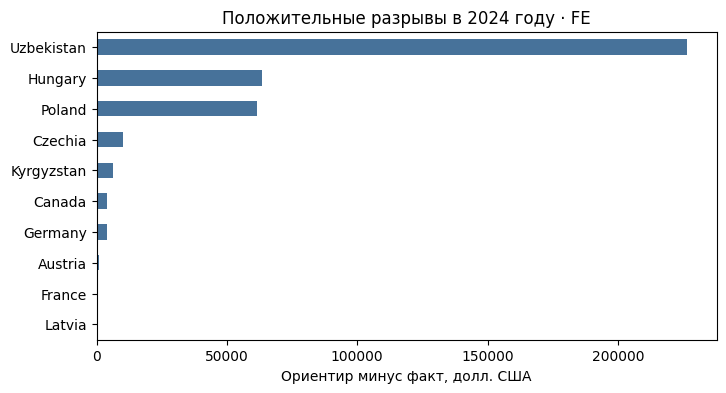

In [ ]:
# Используя модель, выбранную по тесту Хаусмана, построй Top-10.
# Верни fitted из логарифмов в денежную шкалу, затем рассчитай
# G = y_hat - y и g = G / y_hat для последнего года.
last = (common.assign(Ориентир_USD=fitted_usd[chosen]).reset_index()
        .loc[lambda x: x.Year.eq(END)].copy())
last['G_USD'] = last.Ориентир_USD - last.Exports
last['g_pct'] = 100*last.G_USD/last.Ориентир_USD
assert np.isfinite(last[['Ориентир_USD','G_USD','g_pct']]).all().all()
top = last.loc[last.G_USD.gt(0)].sort_values(['G_USD','ISO3'], ascending=[False,True]).head(10)
cols = ['ISO3','Страна','Exports','Ориентир_USD','G_USD','g_pct']
print(f'{END}, {chosen}: {len(last)} рынков в общей панели; '
      f'{int(last.G_USD.gt(0).sum())} положительных разрывов.')
display(top[cols].reset_index(drop=True).rename(index=lambda i: i+1))
if len(top):
    ax = top.iloc[::-1].plot.barh(x='Страна', y='G_USD', legend=False, color='#47729a',
                                 figsize=(8,4), title=f'Положительные разрывы в {END} году · {chosen}')
    ax.set(xlabel='Ориентир минус факт, долл. США', ylabel='')
